In [1]:
import os
import importlib

from pymetropsis.plotting import plot_metropsis_timeseries, plot_metropsis_group

#os.chdir("..")

Figure saved to: /Users/sje30/proj/2020/codecheckers/2026/HeinrichsEtAl_JVis_2026/results/figures/tcs/fig_psychophysics_test_timeseries_212-2.pdf


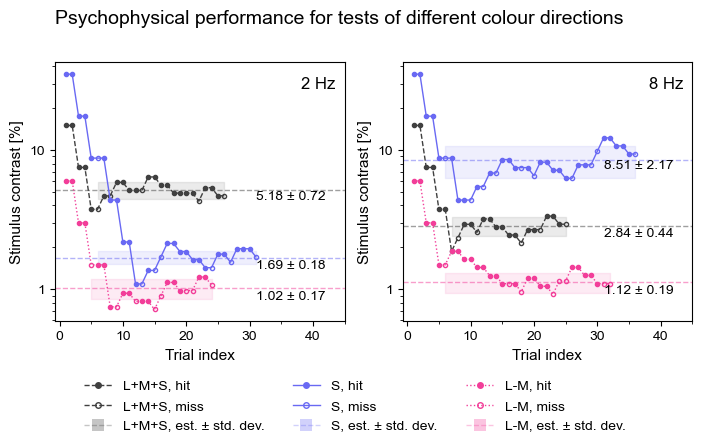

In [2]:
importlib.reload(plot_metropsis_timeseries)
plot_metropsis_timeseries.main()

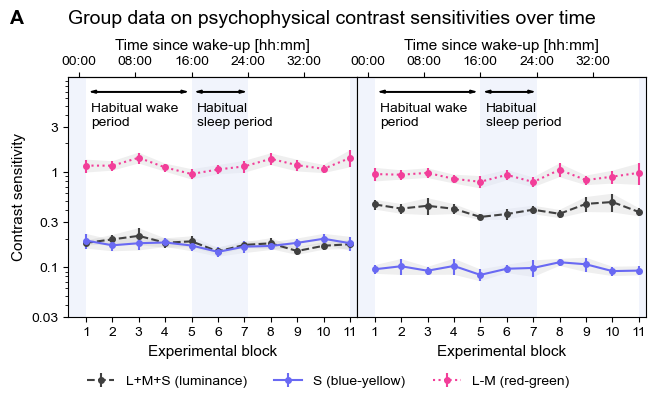

Figure saved to: /Users/sje30/proj/2020/codecheckers/2026/HeinrichsEtAl_JVis_2026/reports/fig/tcs/img_metropsis_blocks_group.pdf


In [7]:
from pymetropsis.plotting.plot_metropsis_group import (
    create_plot_blocks_group_timecourses,
    DATA_DIR#,
    #PROJECT_ROOT,
)

## SJE -- this fix seems to work around the problem.
PROJECT_ROOT = DATA_DIR / ".."

from pymetropsis.plotting.plot_metropsis_group import (
    summarize_contrastsens_by,
)

from pymetropsis.plotting.plot_utils import save_figure
import pandas as pd
from pathlib import Path    

data_path = DATA_DIR / "raw/clean_metropsis_TCS-2e.csv"
meldata_path = DATA_DIR / "raw/clean_saliva_data.csv"
melstat_path = DATA_DIR / "derivatives/hormones/tau_harmonics/melatonin_circadian_parameters.csv"
out_dir = PROJECT_ROOT / "reports/fig"  # "/Users/hheinrichs/Downloads"

# Create output directories
out_dir = Path(out_dir)

# Load data
data = pd.read_csv(data_path)

# Get and merge melatonin data and melatonin circadian statistiics
melraw = pd.read_csv(meldata_path)
melstat = pd.read_csv(melstat_path)
meldata = melraw.merge(melstat, on="participant_id")

# Summarize data across participants
pid_df = summarize_contrastsens_by(
    data=data, group_vars=["participant_id", "block", "condition", "freq"]
)
pid_df.sort_values(by=["participant_id", "condition", "freq", "block"])
median_participant = pid_df["participant_id"].median()  # 206

# Create average plots
fig, _ = create_plot_blocks_group_timecourses(data=pid_df)
fig.set_figheight(4)
fig.set_figwidth(7)
display(fig)
save_figure(fig_dir=out_dir / "tcs", fig_name="img_metropsis_blocks_group.pdf", fig=fig)